# Initial EDA

This notebook explores the raw United Nations General Debate Corpus 1946-2025 (UNGDC) dataset, provided by Harvard Dataverse: https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/0TJX8Y.

## Initial set up

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 150)

DATA_DIR = Path("../data/TXT")

print(f"Data directory exists: {DATA_DIR.exists()}")
print(f"Data directory: {DATA_DIR.resolve()}")

Data directory exists: True
Data directory: /Users/johncreighton/CS6220/International Political Discourse Mining/data/TXT


In [2]:
# Discover files and extract metadata
txt_files = sorted(DATA_DIR.rglob("*.txt"))

print(f"Total text files found: {len(txt_files):,}")
print("\nExample paths:")

for path in txt_files[:10]:
    print(path)

Total text files found: 11,142

Example paths:
../data/TXT/Session 01 - 1946/ARG_01_1946.txt
../data/TXT/Session 01 - 1946/AUS_01_1946.txt
../data/TXT/Session 01 - 1946/BEL_01_1946.txt
../data/TXT/Session 01 - 1946/BLR_01_1946.txt
../data/TXT/Session 01 - 1946/BOL_01_1946.txt
../data/TXT/Session 01 - 1946/BRA_01_1946.txt
../data/TXT/Session 01 - 1946/CAN_01_1946.txt
../data/TXT/Session 01 - 1946/CHL_01_1946.txt
../data/TXT/Session 01 - 1946/CHN_01_1946.txt
../data/TXT/Session 01 - 1946/COL_01_1946.txt


In [3]:
# Build a metadata table from the file paths
records = []

for path in txt_files:
    filename_match = re.match(
        r"([A-Z]{2,3})_(\d+)_(\d{4})\.txt$",
        path.name
    )

    folder_match = re.search(
        r"Session\s+(\d+)\s*-\s*(\d{4})",
        str(path.parent)
    )

    if filename_match:
        country_code = filename_match.group(1)
        session = int(filename_match.group(2))
        year = int(filename_match.group(3))
    else:
        country_code = None
        session = None
        year = None

    records.append({
        "file_path": str(path),
        "filename": path.name,
        "country_code": country_code,
        "session": session,
        "year": year,
        "folder": path.parent.name,
        "folder_session": int(folder_match.group(1)) if folder_match else None,
        "folder_year": int(folder_match.group(2)) if folder_match else None,
    })

metadata = pd.DataFrame(records)

display(metadata.head())

,file_path,filename,country_code,session,year,folder,folder_session,folder_year
0,../data/TXT/Session 01 - 1946/ARG_01_1946.txt,ARG_01_1946.txt,ARG,1.0,1946.0,Session 01 - 1946,1,1946
1,../data/TXT/Session 01 - 1946/AUS_01_1946.txt,AUS_01_1946.txt,AUS,1.0,1946.0,Session 01 - 1946,1,1946
2,../data/TXT/Session 01 - 1946/BEL_01_1946.txt,BEL_01_1946.txt,BEL,1.0,1946.0,Session 01 - 1946,1,1946
3,../data/TXT/Session 01 - 1946/BLR_01_1946.txt,BLR_01_1946.txt,BLR,1.0,1946.0,Session 01 - 1946,1,1946
4,../data/TXT/Session 01 - 1946/BOL_01_1946.txt,BOL_01_1946.txt,BOL,1.0,1946.0,Session 01 - 1946,1,1946


In [4]:
print("Files with unparsed country/session/year:")
display(metadata[metadata["country_code"].isna()])

print("Filename vs. folder metadata mismatches:")
display(
    metadata[
        (metadata["year"] != metadata["folder_year"]) |
        (metadata["session"] != metadata["folder_session"])
    ]
)

Files with unparsed country/session/year:


,file_path,filename,country_code,session,year,folder,folder_session,folder_year
4747,../data/TXT/Session 47 - 1992/.DS_Store-to-UTF-8.txt,.DS_Store-to-UTF-8.txt,None,NaN,NaN,Session 47 - 1992,47,1992


Filename vs. folder metadata mismatches:


,file_path,filename,country_code,session,year,folder,folder_session,folder_year
4747,../data/TXT/Session 47 - 1992/.DS_Store-to-UTF-8.txt,.DS_Store-to-UTF-8.txt,None,NaN,NaN,Session 47 - 1992,47,1992


The output above shows that data/TXT/Session 47 - 1992/.DS_Store-to-UTF-8.txt is the only file that did not match the regex pattern r"([A-Z]{2,3})_(\d+)_(\d{4})\.txt$". This is expected and this file will be excluded from any further analysis.

In [5]:
# Keep only files with successfully parsed metadata
metadata = metadata.dropna(
    subset=["country_code", "session", "year"]
).copy()

metadata["year"] = metadata["year"].astype(int)
metadata["session"] = metadata["session"].astype(int)

print(f"Valid speeches: {len(metadata):,}")
print(f"Unique countries/entities: {metadata['country_code'].nunique()}")

Valid speeches: 11,141
Unique countries/entities: 200


## Read the text files

In [6]:
def read_text_file(path):
    try:
        return path.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        return path.read_text(encoding="latin-1")
    except Exception as e:
        print(f"Error reading {path}: {e}")
        return ""

metadata["text"] = metadata["file_path"].apply(
    lambda x: read_text_file(Path(x))
)

metadata["char_count"] = metadata["text"].str.len()
metadata["word_count"] = metadata["text"].str.split().str.len()
metadata["line_count"] = metadata["text"].str.count(r"\n") + 1

metadata["is_empty"] = metadata["text"].str.strip().eq("")

print(f"Successfully loaded: {(~metadata['is_empty']).sum():,}")
print(f"Empty files: {metadata['is_empty'].sum():,}")

display(
    metadata[
        ["country_code", "year", "word_count", "char_count", "line_count"]
    ].head(10)
)

Successfully loaded: 11,141
Empty files: 0


,country_code,year,word_count,char_count,line_count
0,ARG,1946,3364,19919,48
1,AUS,1946,4531,27862,53
2,BEL,1946,2501,15505,43
3,BLR,1946,3055,18618,51
4,BOL,1946,1501,8631,20
5,BRA,1946,1488,8638,20
6,CAN,1946,1521,9166,19
7,CHL,1946,1376,8463,15
8,CHN,1946,2946,17901,37
9,COL,1946,3861,23047,40


In [7]:
sample = metadata.loc[metadata["word_count"].idxmax()]

print(f"Country: {sample['country_code']}")
print(f"Year: {sample['year']}")
print(f"Words: {sample['word_count']:,}")
print("\nFirst 2,000 characters:\n")
print(sample["text"][:2000])

Country: IND
Year: 1960
Words: 22,003

First 2,000 characters:

I am a newcomer to this Assembly and not accustomed to its ways and conventions. I seek, therefore, the indulgence of the President, and the indulgence of the members of the Assembly for what I have to say.
105.	I have listened attentively and with respect to many of the speeches here, and sometimes I have felt as if I were being buffeted by the icy winds of the cold war. Coming from a warm country, I have shivered occasionally at these cold blasts.
106.	Sitting here in this Assembly chamber, an old  memory comes back to me. In the fateful summer of 1938 I was a visitor at a meeting of the League of Nations in Geneva. Hitler was advancing then and holding out threats of war. There was mobilization in many parts of Europe and the tramp of armoured men was heard, but even so the League of Nations appeared to be unconcerned with the shadow of war and discussed all manner of topics, but not the most vital subject of the day.
1

## Overall dataset statistics

In [8]:
print(f"Total speeches: {len(metadata):,}")
print(f"Unique countries: {metadata['country_code'].nunique():,}")
print(f"Years covered: {metadata['year'].min()}–{metadata['year'].max()}")
print(f"Unique sessions: {metadata['session'].nunique():,}")

display(
    metadata[["word_count", "char_count", "line_count"]].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).round(1)
)

Total speeches: 11,141
Unique countries: 200
Years covered: 1946–2025
Unique sessions: 80


,word_count,char_count,line_count
count,11141.0,11141.0,11141.0
mean,2901.3,18070.4,147.2
std,1496.6,9042.3,143.8
min,423.0,2362.0,1.0
1%,852.4,5321.8,1.0
5%,1253.0,7894.0,17.0
25%,1865.0,11795.0,36.0
50%,2550.0,16013.0,68.0
75%,3622.0,22464.0,248.0
95%,5513.0,34006.0,415.0


### Duplicate check

In [9]:
metadata["text_normalized"] = (
    metadata["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

metadata["text_hash"] = pd.util.hash_pandas_object(
    metadata["text_normalized"],
    index=False
).astype(str)

duplicate_docs = metadata[
    metadata.duplicated("text_hash", keep=False)
].sort_values(["text_hash", "year"])

print(f"Documents involved in exact-text duplicates: {len(duplicate_docs):,}")

display(
    duplicate_docs[
        ["country_code", "year", "filename", "word_count"]
    ].head(30)
)

Documents involved in exact-text duplicates: 0


,country_code,year,filename,word_count


### Coverage over time and space

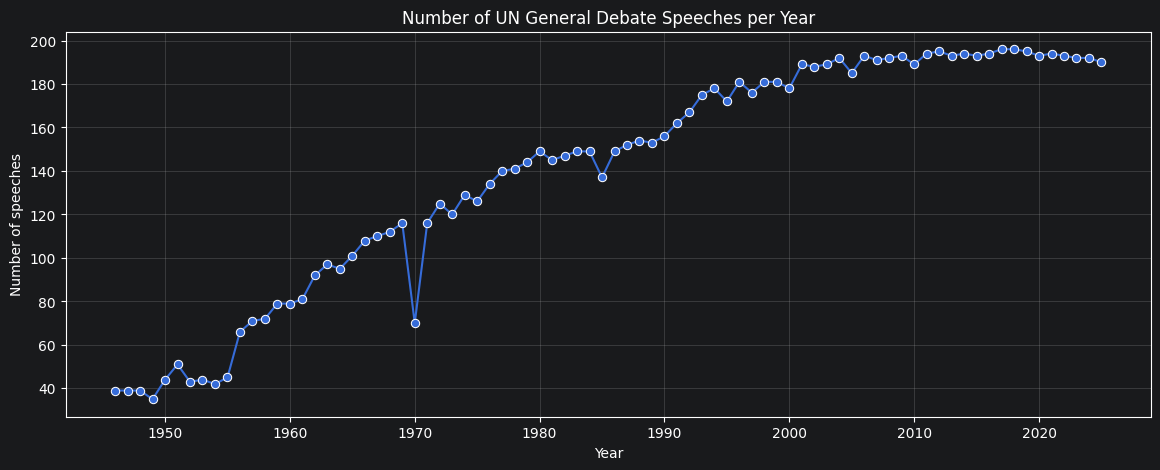

,year,speech_count
count,80.0,80.0
mean,1985.5,139.3
std,23.2,52.9
min,1946.0,35.0
25%,1965.8,100.0
50%,1985.5,149.0
75%,2005.2,189.2
max,2025.0,196.0


In [10]:
# Coverage over time
speeches_per_year = (
    metadata.groupby("year")
    .size()
    .reset_index(name="speech_count")
    .sort_values("year")
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=speeches_per_year, x="year", y="speech_count", marker="o")
plt.title("Number of UN General Debate Speeches per Year")
plt.xlabel("Year")
plt.ylabel("Number of speeches")
plt.grid(alpha=0.3)
plt.show()

display(speeches_per_year.describe().round(1))

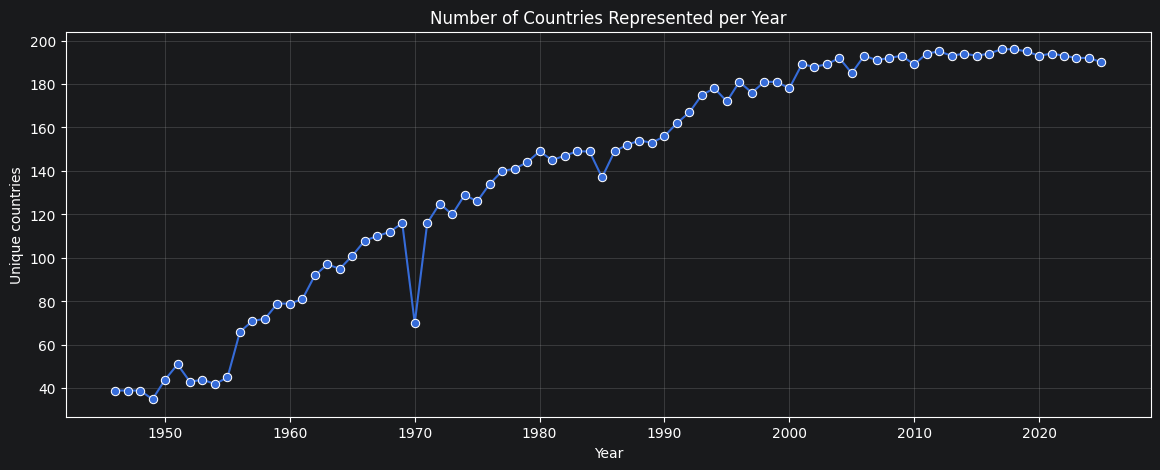

In [11]:
# Countries per year
countries_per_year = (
    metadata.groupby("year")["country_code"]
    .nunique()
    .reset_index(name="country_count")
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=countries_per_year, x="year", y="country_count", marker="o")
plt.title("Number of Countries Represented per Year")
plt.xlabel("Year")
plt.ylabel("Unique countries")
plt.grid(alpha=0.3)
plt.show()

In [12]:
# Check whether each country has exactly one speech per year
country_year_counts = (
    metadata.groupby(["country_code", "year"])
    .size()
    .reset_index(name="speech_count")
)

duplicates = country_year_counts[
    country_year_counts["speech_count"] > 1
].sort_values(["year", "country_code"])

print(f"Total country-year combinations: {len(country_year_counts):,}")
print(f"Country-year combinations with multiple speeches: {len(duplicates):,}")

if duplicates.empty:
    print("Confirmed: Every country has at most one speech per year.")
else:
    print("Multiple speeches found for these country-year combinations:")
    display(duplicates)

Total country-year combinations: 11,141
Country-year combinations with multiple speeches: 0
Confirmed: Every country has at most one speech per year.


### Country coverage

In [13]:
country_summary = (
    metadata.groupby("country_code")
    .agg(
        speech_count=("filename", "count"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        avg_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        years_present=("year", "nunique")
    )
    .sort_values("speech_count", ascending=False)
)

display(country_summary.head(20).round(1))

,speech_count,first_year,last_year,avg_words,median_words,years_present
country_code,,,,,,
BLR,80,1946,2025,3679.8,3708.0,80
GBR,80,1946,2025,3568.8,3263.0,80
ECU,80,1946,2025,3029.4,2947.5,80
NLD,80,1946,2025,2737.7,2554.0,80
USA,80,1946,2025,4058.0,3920.0,80
NZL,80,1946,2025,3165.4,3133.0,80
UKR,80,1946,2025,3542.0,3599.0,80
CAN,80,1946,2025,3238.2,3243.5,80
BRA,80,1946,2025,2828.3,2530.5,80


### Speech length distribution

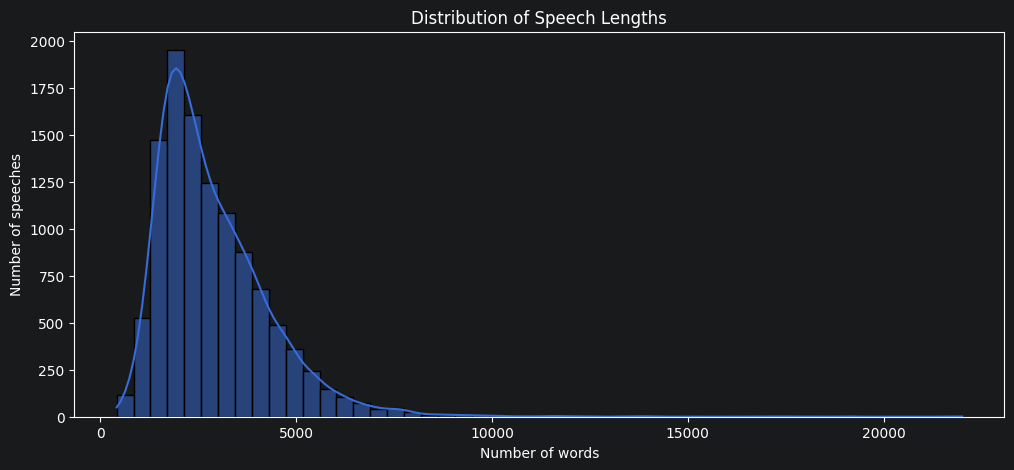

Median speech length: 2550.0
Mean speech length: 2901
Shortest speech: 423
Longest speech: 22003


In [14]:
plt.figure(figsize=(12, 5))
sns.histplot(metadata["word_count"], bins=50, kde=True)
plt.title("Distribution of Speech Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of speeches")
plt.show()

print("Median speech length:", metadata["word_count"].median())
print("Mean speech length:", round(metadata["word_count"].mean()))
print("Shortest speech:", metadata["word_count"].min())
print("Longest speech:", metadata["word_count"].max())

In [15]:
print("10 shortest speeches:")
display(
    metadata.nsmallest(10, "word_count")[
        ["country_code", "year", "word_count", "filename"]
    ]
)

print("10 longest speeches:")
display(
    metadata.nlargest(10, "word_count")[
        ["country_code", "year", "word_count", "filename"]
    ]
)

10 shortest speeches:


,country_code,year,word_count,filename
2044,EGY,1973,423,EGY_28_1973.txt
3960,VCT,1986,462,VCT_41_1986.txt
9220,BEN,2016,463,BEN_71_2016.txt
10247,GNB,2021,480,GNB_76_2021.txt
17,HTI,1946,485,HTI_01_1946.txt
10328,RWA,2021,492,RWA_76_2021.txt
4467,DDR,1990,493,DDR_45_1990.txt
9701,LTU,2018,508,LTU_73_2018.txt
8968,RWA,2014,523,RWA_69_2014.txt
19,IRN,1946,531,IRN_01_1946.txt


10 longest speeches:


,country_code,year,word_count,filename
743,IND,1960,22003,IND_15_1960.txt
727,CUB,1960,21777,CUB_15_1960.txt
236,RUS,1951,19045,RUS_06_1951.txt
900,GIN,1962,18952,GIN_17_1962.txt
396,IND,1955,18053,IND_10_1955.txt
773,RUS,1960,17943,RUS_15_1960.txt
664,IND,1959,17526,IND_14_1959.txt
354,IND,1954,17178,IND_09_1954.txt
617,RUS,1958,16872,RUS_13_1958.txt
311,IND,1953,16080,IND_08_1953.txt


### Initial text-quality checks

In [16]:
# Non-ASCII characters
metadata["non_ascii_count"] = metadata["text"].apply(
    lambda x: sum(not c.isascii() for c in x)
)

# Replacement characters can indicate encoding problems
metadata["replacement_char_count"] = metadata["text"].str.count("\ufffd")

# Words containing digits
metadata["digit_token_count"] = metadata["text"].apply(
    lambda x: sum(bool(re.search(r"\d", token)) for token in x.split())
)

# Tokens with unusual punctuation/symbols
metadata["unusual_token_count"] = metadata["text"].apply(
    lambda x: sum(
        bool(re.search(r"[^A-Za-z0-9'-]", token))
        for token in x.split()
    )
)

print(
    metadata[
        [
            "country_code",
            "year",
            "word_count",
            "non_ascii_count",
            "replacement_char_count",
            "digit_token_count",
            "unusual_token_count"
        ]
    ].describe().round(2)
)

           year  word_count  non_ascii_count  replacement_char_count  \
count  11141.00    11141.00         11141.00                11141.00   
mean    1993.84     2901.26            12.15                    0.00   
std       20.43     1496.56            14.71                    0.06   
min     1946.00      423.00             0.00                    0.00   
25%     1978.00     1865.00             3.00                    0.00   
50%     1996.00     2550.00             9.00                    0.00   
75%     2011.00     3622.00            16.00                    0.00   
max     2025.00    22003.00           292.00                    6.00   

       digit_token_count  unusual_token_count  
count           11141.00             11141.00  
mean               30.43               281.64  
std                29.07               153.47  
min                 0.00                38.00  
25%                11.00               183.00  
50%                20.00               247.00  
75%            

In [17]:
print(
    metadata.nlargest(10, "replacement_char_count")[
        ["country_code", "year", "replacement_char_count", "filename"]
    ]
)

      country_code  year  replacement_char_count         filename
11132          VAT  2025                       6  VAT_80_2025.txt
0              ARG  1946                       0  ARG_01_1946.txt
1              AUS  1946                       0  AUS_01_1946.txt
2              BEL  1946                       0  BEL_01_1946.txt
3              BLR  1946                       0  BLR_01_1946.txt
4              BOL  1946                       0  BOL_01_1946.txt
5              BRA  1946                       0  BRA_01_1946.txt
6              CAN  1946                       0  CAN_01_1946.txt
7              CHL  1946                       0  CHL_01_1946.txt
8              CHN  1946                       0  CHN_01_1946.txt


In [18]:
# Inspect the document containing replacement characters
vat_2025 = metadata[
    metadata["filename"] == "VAT_80_2025.txt"
].iloc[0]["text"]

for match in re.finditer("\ufffd", vat_2025):
    start = max(0, match.start() - 100)
    end = min(len(vat_2025), match.start() + 100)

    print(vat_2025[start:end])
    print("-" * 80)

e last April. As you may all know, when Pope Leo XIV was elected, his first words to the world were �Peace be with you all�, a peace that is unarmed and disarming, humble and persevering. In a word to
--------------------------------------------------------------------------------
ay all know, when Pope Leo XIV was elected, his first words to the world were �Peace be with you all�, a peace that is unarmed and disarming, humble and persevering. In a word torn by wars and conflic
--------------------------------------------------------------------------------
 and conflicts, he made peace to be his first message. Mr. President, the theme chosen for this year�s General Debate �Better Together, Eighty Years and More for Peace, Development and Human Rights� h
--------------------------------------------------------------------------------
 made peace to be his first message. Mr. President, the theme chosen for this year�s General Debate �Better Together, Eighty Years and More for Peace, Dev

Deeper inspection of the VAT_80_2025.txt file reveals that the unusual tokens were simply meant to be quotation marks and apostrophes. # TODO - address this issue

## Initial NLP EDA

### Initial Vocabulary Exploration

In [19]:
import nltk
from nltk.corpus import stopwords

try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords")
    stop_words = set(stopwords.words("english"))

# Add common words that are frequent in formal UN speeches
custom_stopwords = {
    "united", "nations", "nation", "assembly", "general",
    "international", "world", "countries", "country",
    "states", "state", "government", "governments",
    "people", "peoples", "members", "member",
    "organization", "organization's", "session",
    "president", "delegation", "representative",
    "speaker", "today", "year", "years", "must",
    "shall", "may", "would", "could", "should",
    "one", "two", "also", "us", "we", "our"
}

stop_words = stop_words.union(custom_stopwords)

In [20]:
# Tokenize speeches and get most frequent items
def tokenize(text):
    tokens = re.findall(r"[a-zA-Z]{3,}", text.lower())
    return [
        token for token in tokens
        if token not in stop_words
    ]

all_tokens = []

for text in metadata["text"].dropna():
    all_tokens.extend(tokenize(text))

word_counts = Counter(all_tokens)

top_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "frequency"]
)

display(top_words)

,word,frequency
0,peace,114150
1,development,87721
2,security,81050
3,economic,73663
4,new,60059
5,human,50598
6,efforts,47289
7,political,46652
8,community,46352
9,rights,45345


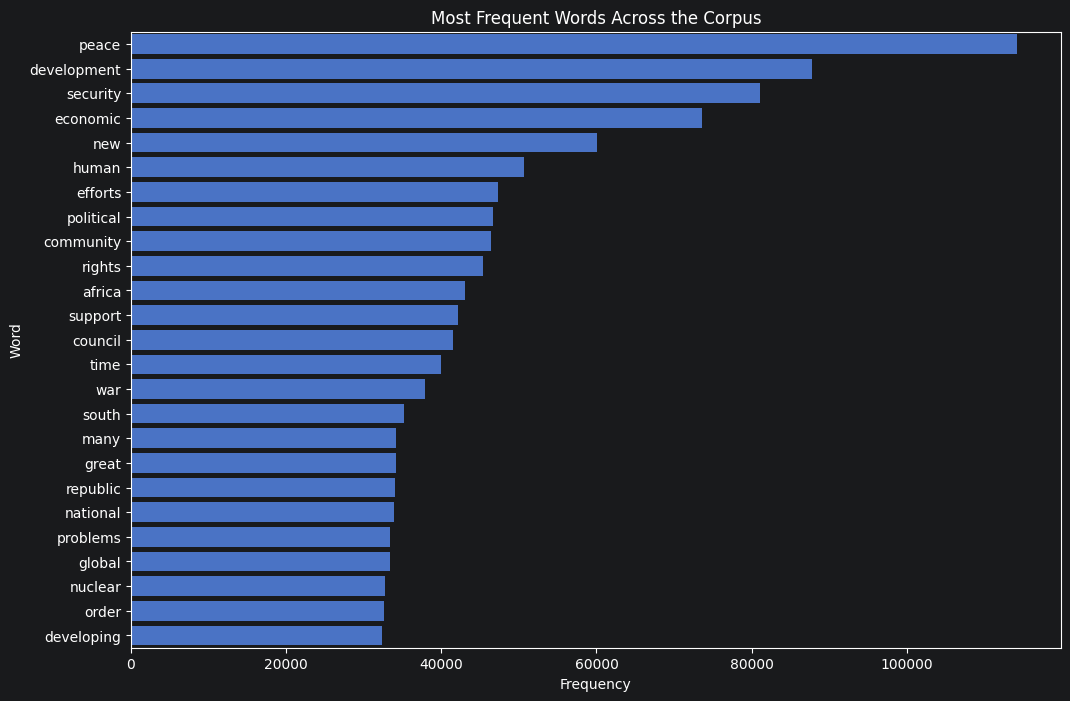

In [21]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_words.head(25),
    x="frequency",
    y="word"
)
plt.title("Most Frequent Words Across the Corpus")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [22]:
# Compare vocabulary across countries
def get_country_word_counts(country_code):
    texts = metadata.loc[
        metadata["country_code"] == country_code, "text"
    ].dropna()

    tokens = []
    for text in texts:
        tokens.extend(tokenize(text))

    return Counter(tokens)

# Choose the five most represented countries
selected_countries = country_summary.head(5).index.tolist()

country_word_counts = {
    country: get_country_word_counts(country)
    for country in selected_countries
}

for country, counts in country_word_counts.items():
    print(f"\n{country}")
    print(counts.most_common(15))


BLR
[('peace', 1217), ('war', 907), ('soviet', 890), ('security', 839), ('new', 701), ('nuclear', 671), ('republic', 663), ('union', 619), ('economic', 588), ('belarus', 566), ('weapons', 563), ('development', 514), ('byelorussian', 511), ('military', 509), ('disarmament', 505)]

GBR
[('peace', 718), ('security', 566), ('new', 521), ('work', 518), ('soviet', 486), ('kingdom', 428), ('first', 419), ('made', 416), ('time', 394), ('need', 386), ('war', 372), ('union', 372), ('make', 370), ('many', 364), ('problems', 356)]

ECU
[('ecuador', 1252), ('peace', 778), ('development', 649), ('economic', 647), ('human', 552), ('rights', 474), ('new', 448), ('social', 431), ('security', 392), ('political', 390), ('problems', 364), ('great', 343), ('charter', 333), ('latin', 321), ('american', 314)]

NLD
[('netherlands', 827), ('peace', 665), ('human', 623), ('rights', 581), ('security', 569), ('development', 531), ('economic', 483), ('new', 460), ('council', 426), ('political', 380), ('many', 338